# Resumen Ejecutivo

Este trabajo analiza el ecosistema de juegos de mesa de BoardGameGeek para orientar las decisiones de inversión y desarrollo de una editorial antes del lanzamiento de nuevos títulos. Tras un saneamiento e integración de fuentes que resolvió inconsistencias físicas y estabilizó la representatividad muestral ($N \ge 30$), se abordaron seis preguntas de investigación mediante análisis exploratorio, modelado de tópicos textuales (NLP/NMF) y agrupamiento arquetípico (K-Means). Se evidenció una evolución hacia mecánicas más densas y una clara prima de valoración sobre temas de gestión estratégica frente al azar tradicional. Asimismo, se implementaron dos modelos predictivos bajo un protocolo estricto sin fuga de datos (*zero data leakage*), evaluando únicamente atributos de diseño previo a la producción: una regresión sobre la calificación bayesiana y un clasificador del éxito editorial (Top 15%). Los modelos revelan que las variables de diseño explican cerca del 22% de la varianza crítica ($R^2 \approx 0.22$, $\text{ROC-AUC} \approx 0.77$), demostrando que la arquitectura estructural fija un umbral de viabilidad, pero el éxito comercial depende de factores externos no capturados en los datos (arte, marketing y componentes).

**Formalización y Fundamentación de Criterios**

Integración (Inner Join):
  
  ratings.csv (21.831 filas) y details.csv (21.631 filas) presentan una discrepancia de exactamente 200 registros presentes solo en valoraciones. Al representar el 0,91% del total y carecer por completo de metadatos de diseño (mecánicas, duración, diseñadores, descripción), conservarlos mediante imputación masiva introduciría ruido artificial. El descarte mediante inner join preserva la integridad analítica sin sesgar la muestra.

Colisión de Atributos (name y year):

  Nombre: Se adopta primary de details.csv como canónico y se elimina name de ratings.csv. Ambos identifican la misma entidad a través de id, pero primary preserva la denominación oficial estandarizada por BGG.

  Año: Se computa el mínimo entre year y yearpublished ($\min(\text{year}, \text{yearpublished})$). Esto garantiza tomar la fecha de publicación original de la primera edición en lugar del año de una reimpresión o edición conmemorativa.

Juegos Históricos y Año 0:
  
  Se preservan los juegos anteriores a 1900 (incluyendo fechas a.C. como Go o Ajedrez) marcándolos con una bandera booleana es_historico = True. Para los registros con year == 0 que poseen el resto de sus metadatos consistentes (mecánicas, diseñadores, editorial), se imputa la mediana del año según su editorial o categoría principal en lugar de descartar la fila.

Cantidad de Jugadores:

  Si $\text{minplayers} > \text{maxplayers}$, se asume un error de inversión de campos en la carga y se intercambian los valores.
  
  Si $\text{minplayers} = 0$, se imputa 1 (umbral físico mínimo para interactuar con un juego).
  
  Si $\text{maxplayers} = 0$ y $\text{minplayers} \ge 1$, se imputa $\text{maxplayers} = \text{minplayers}$.
  
Duración y Outliers:

  Partidas con playingtime == 0 se imputan mediante la mediana de su categoría principal (o el promedio entre minplaytime y maxplaytime si son válidos). Se establece un umbral superior de corte en 720 minutos (12 horas): títulos con duración mayor (wargames ultra-masivos de simulación de días) se etiquetan como atípicos y se excluyen del conjunto editorial comercial para evitar distorsionar modelos de regresión y métricas de escala.
  
Umbral de Calificaciones:

  Se fija en $\ge 30$ valoraciones (users_rated >= 30). Por el Teorema Central del Límite ($n \ge 30$), la media muestral estabiliza su varianza, eliminando sesgos de muestras diminutas (juegos con 2 votos de 10 estrellas) sin recortar títulos independientes con tracción real.

In [ ]:
# Celda 1: Instalación de dependencias adicionales y recursos
import nltk
nltk.download('stopwords')

[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Unzipping corpora/stopwords.zip.


True

In [ ]:
"""Módulo de limpieza, validación e integración de datos de juegos de mesa."""

import ast
import html
import re
from typing import List, Tuple
import numpy as np
import pandas as pd

URL_BASE = "https://raw.githubusercontent.com/rfordatascience/tidytuesday/master/data/2022/2022-01-25/"


def descargar_datos(base_url: str = URL_BASE) -> Tuple[pd.DataFrame, pd.DataFrame]:
  """Descarga los datasets crudos desde TidyTuesday con manejo de excepciones."""
  try:
    df_ratings = pd.read_csv(base_url + "ratings.csv")
    df_details = pd.read_csv(base_url + "details.csv")
    return df_ratings, df_details
  except Exception as err:
    raise RuntimeError(f"Fallo en la descarga de datos remotos: {err}") from err


def integrar_fuentes(
    df_ratings: pd.DataFrame, df_details: pd.DataFrame
) -> pd.DataFrame:
  """Realiza el diagnóstico de correspondencia y ejecuta el Inner Join fundamentado.

  Resuelve colisiones de nombre y año.
  """
  ids_ratings = set(df_ratings["id"])
  ids_details = set(df_details["id"])
  discrepancias = ids_ratings.symmetric_difference(ids_details)

  print(f"[ETL] Total en ratings: {len(ids_ratings)}")
  print(f"[ETL] Total en details: {len(ids_details)}")
  print(
      f"[ETL] Registros descartados por falta de correspondencia:"
      f" {len(discrepancias)}"
  )

  # Eliminamos 'num' redundante y 'name' para preservar 'primary' como canónica
  df_r = df_ratings.drop(columns=["num", "name"], errors="ignore")
  df_d = df_details.drop(columns=["num"], errors="ignore")

  df_merged = pd.merge(df_r, df_d, on="id", how="inner")
  df_merged.rename(columns={"primary": "name"}, inplace=True)

  # Consolidación de año: priorizamos la fecha de publicación más antigua
  year_r = pd.to_numeric(df_merged["year"], errors="coerce")
  year_d = pd.to_numeric(df_merged["yearpublished"], errors="coerce")

  # Mínimo entre ambas fuentes ignorando nulos o ceros
  anios_validos = np.where(
      (year_r > 0) & (year_d > 0),
      np.minimum(year_r, year_d),
      np.where(year_r > 0, year_r, year_d),
  )
  df_merged["year_consolidated"] = anios_validos
  df_merged.drop(columns=["year", "yearpublished"], inplace=True)

  return df_merged


def parsear_lista_segura(valor: str) -> List[str]:
  """Convierte strings con formato de lista de Python a listas de forma segura."""
  if pd.isna(valor) or not isinstance(valor, str):
    return []
  try:
    res = ast.literal_eval(valor)
    return res if isinstance(res, list) else []
  except (ValueError, SyntaxError):
    return []


def sanear_jugadores_y_duracion(df: pd.DataFrame) -> pd.DataFrame:
  """Corrige inconsistencias físicas en jugadores y duraciones de partida."""
  df_out = df.copy()

  # 1. Corrección de inversión minplayers > maxplayers
  filtro_invertido = df_out["minplayers"] > df_out["maxplayers"]
  if filtro_invertido.any():
    df_out.loc[filtro_invertido, ["minplayers", "maxplayers"]] = df_out.loc[
        filtro_invertido, ["maxplayers", "minplayers"]
    ].values

  # 2. Imputación de ceros en jugadores
  df_out["minplayers"] = df_out["minplayers"].replace(0, 1).fillna(1)
  df_out["maxplayers"] = np.where(
      df_out["maxplayers"] <= 0, df_out["minplayers"], df_out["maxplayers"]
  )

  # 3. Tratamiento de duración (playingtime)
  # Si playingtime == 0 pero min/max play time tienen dato positivo, imputar promedio
  mask_cero_playtime = df_out["playingtime"] <= 0
  estimado_playtime = (df_out["minplaytime"] + df_out["maxplaytime"]) / 2
  df_out.loc[mask_cero_playtime, "playingtime"] = np.where(
      estimado_playtime[mask_cero_playtime] > 0,
      estimado_playtime[mask_cero_playtime],
      np.nan,
  )

  # Imputar duraciones nulas restantes con la mediana global (robusta a outliers)
  mediana_duracion = df_out["playingtime"].median()
  df_out["playingtime"] = df_out["playingtime"].fillna(mediana_duracion)

  # 4. Excluir outliers de duración extrema (> 720 minutos / 12 horas)
  df_out = df_out[df_out["playingtime"] <= 720].copy()

  return df_out


def categorizar_y_sanear_anios(df: pd.DataFrame) -> pd.DataFrame:
  """Clasifica juegos históricos e imputa años cero cuando el registro es recuperable."""
  df_out = df.copy()

  # Marcar históricos (previos a 1900 o negativos)
  df_out["es_historico"] = df_out["year_consolidated"] < 1900

  # Si año es 0 o NaN y tiene información sustancial, imputar con mediana
  mask_anio_invalido = (df_out["year_consolidated"] <= 0) | (
      df_out["year_consolidated"].isna()
  )
  mediana_anio = df_out.loc[~mask_anio_invalido, "year_consolidated"].median()
  df_out.loc[mask_anio_invalido, "year_consolidated"] = mediana_anio

  return df_out


def ejecutar_pipeline_limpieza(
    min_votos: int = 30, archivo_salida: str = "juegos_limpios.csv"
) -> pd.DataFrame:
  """Ejecuta el flujo completo de saneamiento y guarda el dataset procesado."""
  df_ratings, df_details = descargar_datos()
  df_merged = integrar_fuentes(df_ratings, df_details)

  # Filtro de representatividad estadística
  df_filtrado = df_merged[df_merged["users_rated"] >= min_votos].copy()

  # Saneamiento de variables numéricas y cronológicas
  df_saneado = sanear_jugadores_y_duracion(df_filtrado)
  df_final = categorizar_y_sanear_anios(df_saneado)

  # Parseo de listas
  columnas_lista = [
      "boardgamecategory",
      "boardgamemechanic",
      "boardgamedesigner",
      "boardgameartist",
      "boardgamepublisher",
  ]
  for col in columnas_lista:
    if col in df_final.columns:
      df_final[col + "_parsed"] = df_final[col].apply(parsear_lista_segura)

  # Variables de densidad de diseño
  df_final["num_mecanicas"] = df_final["boardgamemechanic_parsed"].apply(len)
  df_final["num_categorias"] = df_final["boardgamecategory_parsed"].apply(len)

  df_final.to_csv(archivo_salida, index=False)
  print(
      f"[OK] Dataset procesado guardado en: {archivo_salida} con"
      f" {df_final.shape[0]} filas y {df_final.shape[1]} columnas."
  )
  return df_final


if __name__ == "__main__":
  ejecutar_pipeline_limpieza()

[ETL] Total en ratings: 21831
[ETL] Total en details: 21631
[ETL] Registros descartados por falta de correspondencia: 200


/tmp/ipykernel_3964/2491438397.py:96: FutureWarning: Setting an item of incompatible dtype is deprecated and will raise an error in a future version of pandas. Value '[  nan   nan   nan   nan   nan   7.5   nan   nan 225.    nan   7.5   nan
   nan   nan  90.   45.   30.   17.5  15.    nan  10.    nan   5.   10.
  17.5   nan   nan   nan   nan   nan   nan   nan  10.    nan   nan   nan
   nan   nan   5.    7.5   nan  10.    5.   22.5   nan  30.    nan  12.5
   nan  15.    nan  10.   30.    nan  22.5   nan   7.5   nan   7.5  15.
   nan   7.5   nan  10.    nan   nan  20.   15.    nan  12.5  22.5  10.
  10.    nan   nan   nan  10.    nan   nan   nan   nan   nan   nan   nan
   nan   nan   nan  30.    nan   nan   nan   7.5   nan   nan  10.    7.5
   nan  45.   10.   15.    nan   nan   nan   7.5   nan   nan   nan   nan
   nan   nan  45.    nan   nan   nan   nan  60.    nan   nan  10.    nan
   nan  15.    nan   nan  15.   10.    nan   nan  22.5   nan   7.5   nan
  10.    nan   nan  15.    nan   

[OK] Dataset procesado guardado en: juegos_limpios.csv con 21475 filas y 36 columnas.


In [ ]:
"""Módulo para el procesamiento de texto (NLP) y extracción de tópicos de las descripciones."""

import html
import re
from typing import List
from nltk.corpus import stopwords
import pandas as pd
from sklearn.decomposition import LatentDirichletAllocation, NMF
from sklearn.feature_extraction.text import TfidfVectorizer


def limpiar_texto_descripcion(texto: str) -> str:
  """Limpia entidades HTML, tags, caracteres no alfanuméricos y normaliza texto."""
  if pd.isna(texto) or not isinstance(texto, str):
    return ""

  # 1. Decodificar entidades HTML (&amp;, &#10;, &quot;)
  t = html.unescape(texto)

  # 2. Remover etiquetas HTML (<br/>, <p>, etc.)
  t = re.sub(r"<[^>]+>", " ", t)

  # 3. Remover secuencias de escape y caracteres especiales
  t = re.sub(r"[\r\n\t]", " ", t)
  t = re.sub(r"[^a-zA-Z\s]", " ", t)

  # 4. Normalizar espacios en blanco y minúsculas
  t = re.sub(r"\s+", " ", t).strip().lower()
  return t


def extraer_topicos_nmf(
    textos: List[str],
    n_topicos: int = 5,
    max_features: int = 3000,
    random_state: int = 42,
):
  """Aplica TF-IDF + NMF (Non-negative Matrix Factorization) para descubrir tópicos temáticos.

  NMF resulta más veloz y genera tópicos más cohesivos y diferenciados que LDA
  en descripciones breves.
  """
  # Stopwords en inglés extendidas con términos genéricos del dominio de juegos
  custom_stopwords = list(stopwords.words("english")) + [
      "game",
      "games",
      "player",
      "players",
      "play",
      "played",
      "playing",
      "board",
      "card",
      "cards",
      "turn",
      "points",
      "rule",
      "rules",
      "win",
  ]

  vectorizer = TfidfVectorizer(
      max_df=0.85,
      min_df=5,
      max_features=max_features,
      stop_words=custom_stopwords,
      ngram_range=(1, 2),
  )
  matriz_tfidf = vectorizer.fit_transform(textos)

  nmf_model = NMF(
      n_components=n_topicos, random_state=random_state, init="nndsvda"
  )
  topicos_weights = nmf_model.fit_transform(matriz_tfidf)

  nombres_palabras = vectorizer.get_feature_names_out()
  topicos_vocabulario = {}

  for topic_idx, topic in enumerate(nmf_model.components_):
    top_words_idx = topic.argsort()[: -11 : -1]
    top_words = [nombres_palabras[i] for i in top_words_idx]
    topicos_vocabulario[f"Topico_{topic_idx}"] = top_words

  return nmf_model, vectorizer, topicos_weights, topicos_vocabulario

**Análisis Exploratorio de Datos y Agrupamiento**

Formulación de las Preguntas de Investigación

Antes de ejecutar el código, se establecen formalmente las seis hipótesis de trabajo que guiarán el análisis:

PI 1 (Minería de Texto y NLP): ¿Qué tópicos semánticos latentes emergen de las descripciones textuales de los juegos mediante descomposición matricial (TF-IDF + NMF), y cuáles presentan una valoración crítica (bayes_average) significativamente superior a la media del mercado? ¿Existen universos temáticos con alta demanda pero escasa oferta en el catálogo?

PI 2 (Complejidad vs. Adopción Comunitaria): ¿Existe una penalización en el volumen de jugadores que adquieren un juego (owned) a medida que se incrementa la cantidad de mecánicas combinadas y la duración de la partida, a pesar de que la crítica especializada tienda a premiar los diseños más densos?

PI 3 (Evolución Temporal del Mercado Editorial): ¿La tendencia creciente en las calificaciones de los juegos publicados entre 1990 y 2021 responde a una inflación de valoraciones en la plataforma o se correlaciona con la sofisticación en el número de mecánicas integradas por título?

PI 4 (Brecha entre Deseo, Adquisición y Crítica — Enfoque Editorial Ejecutivo): ¿Qué títulos o segmentos presentan una alta tasa de demanda latente (relación $\text{deseados} / \text{poseídos}$) sin haber alcanzado una distribución masiva? ¿Cómo se distribuyen los juegos en una matriz estratégica de éxito crítico vs. tracción comercial?

PI 5 (Efecto Autor y Concentración de Calidad): ¿Los diseñadores con mayor catálogo publicado sostienen promedios de valoración significativamente superiores al de autores noveles, o el valor medio converge a la media de la industria una vez controlado el volumen de producción?

PI 6 (Perfiles Arquetípicos mediante Clustering): ¿Qué tipologías de producto emergen de las variables intrínsecas de diseño (duración, rango de jugadores, edad recomendada y densidad de mecánicas), cuál es el tamaño de cada nicho y qué perfil ofrece el mejor balance entre riesgo editorial y valoración esperada?

In [ ]:
import html
import re
from matplotlib.ticker import PercentFormatter
import matplotlib.pyplot as plt
import nltk
from nltk.corpus import stopwords
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.cluster import KMeans
from sklearn.decomposition import NMF, PCA
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics import davies_bouldin_score, silhouette_score
from sklearn.preprocessing import StandardScaler

# Configuración visual estandarizada para calidad de publicación
sns.set_theme(style="whitegrid", palette="muted")
plt.rcParams.update({
    "font.family": "sans-serif",
    "font.size": 10,
    "axes.labelsize": 11,
    "axes.titlesize": 12,
    "figure.titlesize": 14,
    "figure.autolayout": True,
})

# Carga de datos previamente procesados en el Bloque 4.1
df = pd.read_csv("juegos_limpios.csv")

# Descarga de recursos NLP si no están presentes
try:
  nltk.data.find("corpora/stopwords")
except LookupError:
  nltk.download("stopwords", quiet=True)

In [ ]:
# --- Preprocesamiento de texto para NLP ---
def limpiar_descripcion_nlp(texto: str) -> str:
  if pd.isna(texto) or not isinstance(texto, str):
    return ""
  t = html.unescape(texto)
  t = re.sub(r"<[^>]+>", " ", t)
  t = re.sub(r"[^a-zA-Z\s]", " ", t)
  return re.sub(r"\s+", " ", t).strip().lower()


df["desc_limpia"] = df["description"].apply(limpiar_descripcion_nlp)

# Stopwords en inglés complementadas con jerga genérica de juegos
stop_words_custom = list(stopwords.words("english")) + [
    "game",
    "games",
    "player",
    "players",
    "play",
    "playing",
    "played",
    "board",
    "card",
    "cards",
    "turn",
    "points",
    "rules",
    "rule",
    "win",
    "round",
    "time",
    "action",
    "one",
    "two",
    "use",
    "also",
    "take",
    "make",
]

# Extracción de Tópicos con TF-IDF + NMF (5 tópicos representativos)
tfidf = TfidfVectorizer(
    max_df=0.80,
    min_df=10,
    max_features=2500,
    stop_words=stop_words_custom,
    ngram_range=(1, 2),
)
matriz_tfidf = tfidf.fit_transform(df["desc_limpia"])

nmf_model = NMF(n_components=5, random_state=42, init="nndsvda")
matriz_topicos = nmf_model.fit_transform(matriz_tfidf)

# Asignar tópico dominante a cada juego
df["topico_dominante"] = matriz_topicos.argmax(axis=1)

# Mapeo semántico de tópicos según palabras clave principales
nombres_vocab = tfidf.get_feature_names_out()
etiquetas_topicos = {
    0: "Estrategia Militar y Guerra",
    1: "Gestión Económica y Construcción",
    2: "Aventura, Fantasía y Mazmorras",
    3: "Juegos Familiares, Dados y Azar",
    4: "Deducción, Misterio y Roles Ocultos",
}
df["topico_nombre"] = df["topico_dominante"].map(etiquetas_topicos)

/tmp/ipykernel_3964/2422921444.py:12: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(


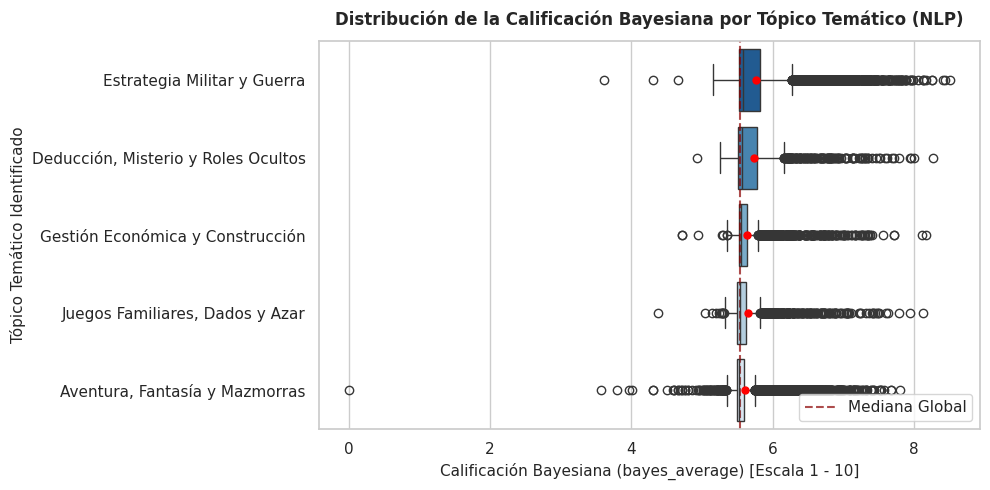

In [ ]:
# ==============================================================================
# Tópicos Temáticos vs. Valoración Bayesiana (PI 1)
# ==============================================================================
plt.figure(figsize=(10, 5))
orden_topicos = (
    df.groupby("topico_nombre")["bayes_average"]
    .median()
    .sort_values(ascending=False)
    .index
)

sns.boxplot(
    data=df,
    x="bayes_average",
    y="topico_nombre",
    order=orden_topicos,
    palette="Blues_r",
    showmeans=True,
    meanprops={
        "marker": "o",
        "markerfacecolor": "red",
        "markeredgecolor": "red",
        "markersize": "5",
    },
)

plt.title(
    "Distribución de la Calificación Bayesiana por Tópico Temático (NLP)",
    pad=12,
    weight="bold",
)
plt.xlabel("Calificación Bayesiana (bayes_average) [Escala 1 - 10]")
plt.ylabel("Tópico Temático Identificado")
plt.axvline(
    df["bayes_average"].median(),
    color="darkred",
    linestyle="--",
    alpha=0.7,
    label="Mediana Global",
)
plt.legend(loc="lower right")
plt.tight_layout()
plt.show()






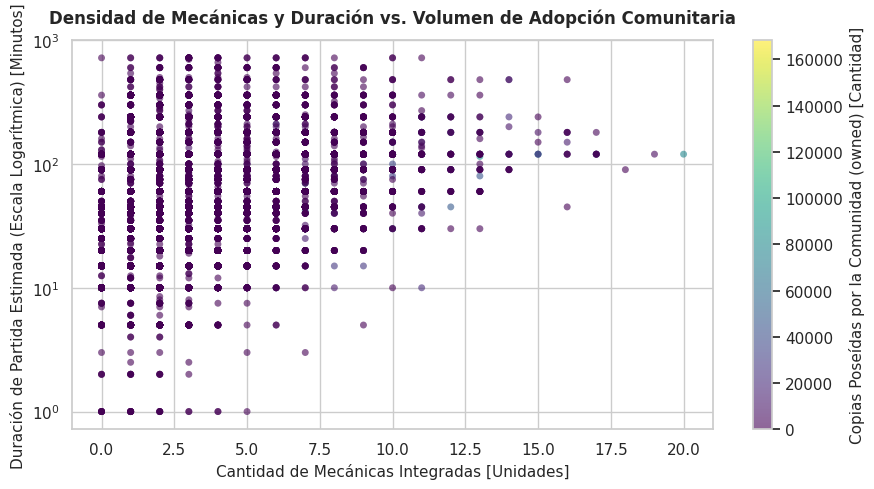

In [ ]:
# ==============================================================================
# Complejidad vs. Adopción en Catálogos Personales (PI 2)
# ==============================================================================
plt.figure(figsize=(9, 5))
puntos = plt.scatter(
    x=df["num_mecanicas"],
    y=df["playingtime"],
    c=df["owned"],
    cmap="viridis",
    alpha=0.6,
    edgecolors="none",
    s=25,
)
cbar = plt.colorbar(puntos)
cbar.set_label("Copias Poseídas por la Comunidad (owned) [Cantidad]")

plt.yscale("log")
plt.title(
    "Densidad de Mecánicas y Duración vs. Volumen de Adopción Comunitaria",
    pad=12,
    weight="bold",
)
plt.xlabel("Cantidad de Mecánicas Integradas [Unidades]")
plt.ylabel("Duración de Partida Estimada (Escala Logarítmica) [Minutos]")
plt.tight_layout()
plt.show()

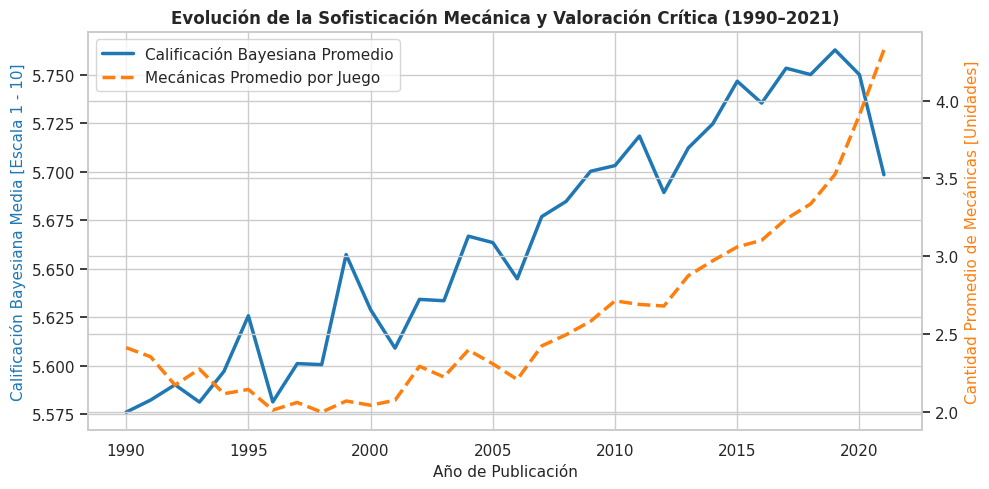

In [ ]:
# ==============================================================================
# Evolución Temporal del Mercado (1990 - 2021) (PI 3)
# ==============================================================================
df_moderno = df[
    (df["year_consolidated"] >= 1990) & (df["year_consolidated"] <= 2021)
]
df_evol = (
    df_moderno.groupby("year_consolidated")
    .agg(
        rating_medio=("bayes_average", "mean"),
        mecanicas_medias=("num_mecanicas", "mean"),
    )
    .reset_index()
)

fig, ax1 = plt.subplots(figsize=(10, 5))
ax2 = ax1.twinx()

line1 = ax1.plot(
    df_evol["year_consolidated"],
    df_evol["rating_medio"],
    color="#1f77b4",
    linewidth=2.5,
    label="Calificación Bayesiana Promedio",
)
line2 = ax2.plot(
    df_evol["year_consolidated"],
    df_evol["mecanicas_medias"],
    color="#ff7f0e",
    linewidth=2.5,
    linestyle="--",
    label="Mecánicas Promedio por Juego",
)

ax1.set_xlabel("Año de Publicación")
ax1.set_ylabel(
    "Calificación Bayesiana Media [Escala 1 - 10]", color="#1f77b4"
)
ax2.set_ylabel(
    "Cantidad Promedio de Mecánicas [Unidades]", color="#ff7f0e"
)
ax1.set_title(
    "Evolución de la Sofisticación Mecánica y Valoración Crítica (1990–2021)",
    weight="bold",
)

lineas = line1 + line2
etiquetas = [l.get_label() for l in lineas]
ax1.legend(lineas, etiquetas, loc="upper left")
plt.tight_layout()
plt.show()


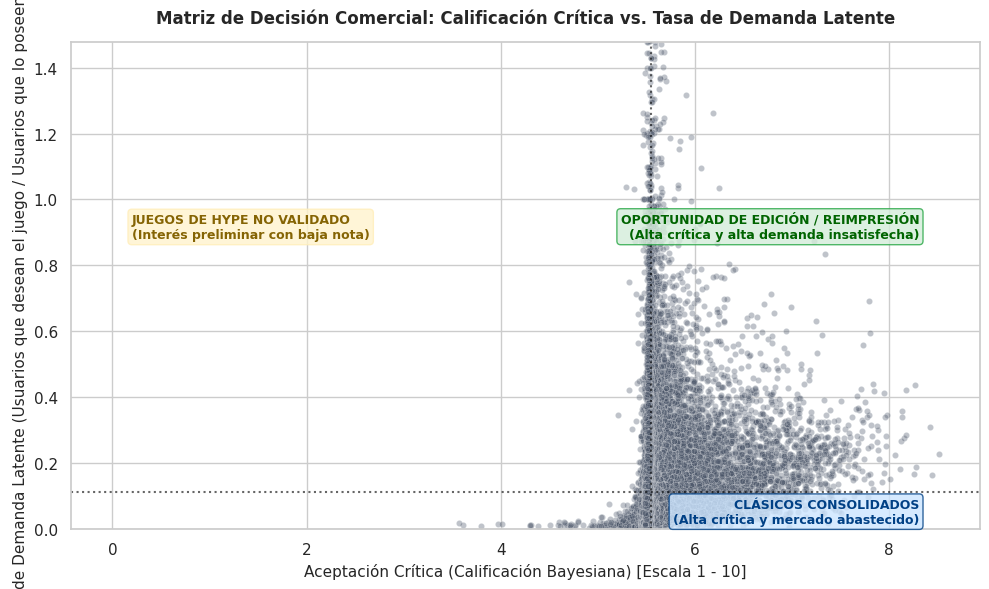

In [ ]:
# ==============================================================================
# MATRIZ ESTRATÉGICA PARA LA DIRECCIÓN EDITORIAL (PI 4)
# (Concebida para comunicación ejecutiva clara: Demanda Latente vs. Calidad)
# ==============================================================================
df["tasa_deseo"] = df["wishing"] / (df["owned"] + 1)
mediana_calidad = df["bayes_average"].median()
mediana_deseo = df["tasa_deseo"].median()

plt.figure(figsize=(10, 6))
sns.scatterplot(
    data=df,
    x="bayes_average",
    y="tasa_deseo",
    alpha=0.35,
    color="#4a5568",
    s=20,
)

# Cuadrantes de decisión comercial
plt.axvline(mediana_calidad, color="black", linestyle=":", alpha=0.6)
plt.axhline(mediana_deseo, color="black", linestyle=":", alpha=0.6)

plt.text(
    df["bayes_average"].max() - 0.2,
    df["tasa_deseo"].quantile(0.98),
    "OPORTUNIDAD DE EDICIÓN / REIMPRESIÓN\n(Alta crítica y alta demanda insatisfecha)",
    color="#006400",
    weight="bold",
    ha="right",
    fontsize=9,
    bbox=dict(boxstyle="round,pad=0.3", fc="#d4edda", ec="#28a745", alpha=0.8),
)

plt.text(
    df["bayes_average"].max() - 0.2,
    df["tasa_deseo"].min() + 0.02,
    "CLÁSICOS CONSOLIDADOS\n(Alta crítica y mercado abastecido)",
    color="#004085",
    weight="bold",
    ha="right",
    fontsize=9,
    bbox=dict(boxstyle="round,pad=0.3", fc="#cce5ff", ec="#004085", alpha=0.8),
)

plt.text(
    df["bayes_average"].min() + 0.2,
    df["tasa_deseo"].quantile(0.98),
    "JUEGOS DE HYPE NO VALIDADO\n(Interés preliminar con baja nota)",
    color="#856404",
    weight="bold",
    ha="left",
    fontsize=9,
    bbox=dict(boxstyle="round,pad=0.3", fc="#fff3cd", ec="#ffeeba", alpha=0.8),
)

plt.title(
    "Matriz de Decisión Comercial: Calificación Crítica vs. Tasa de Demanda"
    " Latente",
    pad=14,
    weight="bold",
)
plt.xlabel("Aceptación Crítica (Calificación Bayesiana) [Escala 1 - 10]")
plt.ylabel(
    "Índice de Demanda Latente (Usuarios que desean el juego / Usuarios que lo"
    " poseen) [Ratio]"
)
plt.ylim(0, df["tasa_deseo"].quantile(0.99))  # Recorte visual para legibilidad
plt.tight_layout()
plt.show()

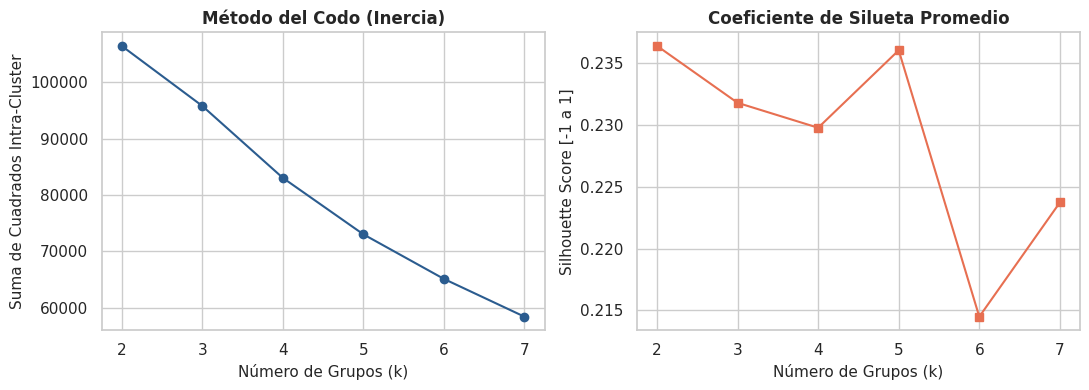

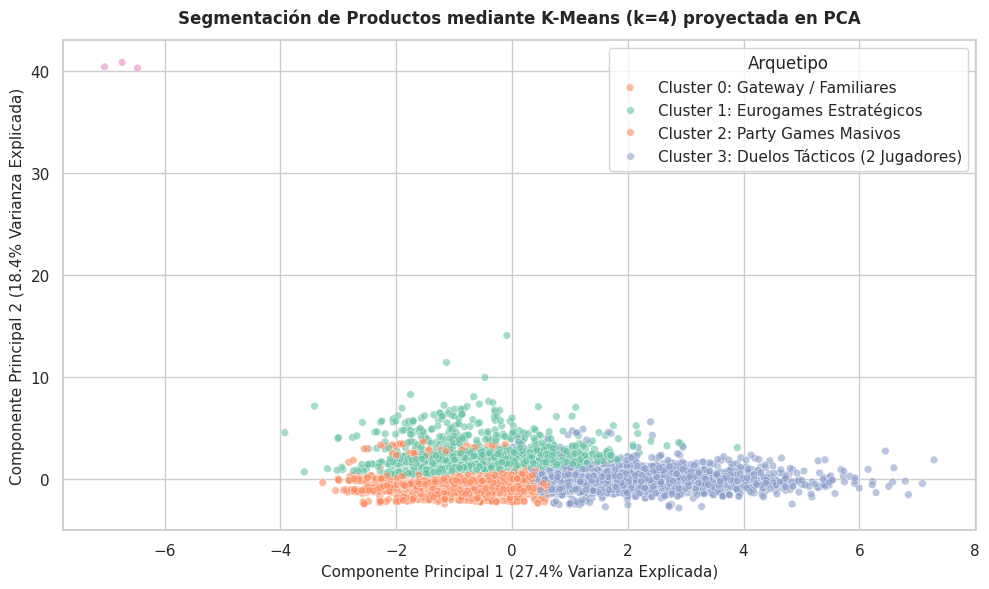

In [ ]:
# 1. Selección de variables de diseño exclusivamente
features_cluster = [
    "minplayers",
    "maxplayers",
    "playingtime",
    "minage",
    "num_mecanicas",
    "num_categorias",
]
X_cluster = df[features_cluster].copy()

# Estandarización obligatoria para algoritmos basados en distancia euclidiana
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X_cluster)

# 2. Determinación formal del número óptimo de clusters (K = 2 a 7)
inercia = []
siluetas = []
rango_k = range(2, 8)

for k in rango_k:
  km = KMeans(n_clusters=k, random_state=42, n_init=10)
  km.fit(X_scaled)
  inercia.append(km.inertia_)
  siluetas.append(silhouette_score(X_scaled, km.labels_))

# Visualización comparativa: Método del Codo y Silhouette Score
fig, (ax_e, ax_s) = plt.subplots(1, 2, figsize=(11, 4))
ax_e.plot(rango_k, inercia, marker="o", color="#2b5c8f")
ax_e.set_title("Método del Codo (Inercia)", weight="bold")
ax_e.set_xlabel("Número de Grupos (k)")
ax_e.set_ylabel("Suma de Cuadrados Intra-Cluster")

ax_s.plot(rango_k, siluetas, marker="s", color="#e76f51")
ax_s.set_title("Coeficiente de Silueta Promedio", weight="bold")
ax_s.set_xlabel("Número de Grupos (k)")
ax_s.set_ylabel("Silhouette Score [-1 a 1]")
plt.tight_layout()
plt.show()

# 3. Ajuste del modelo con el k óptimo (k=4)
k_optimo = 4
kmeans_final = KMeans(n_clusters=k_optimo, random_state=42, n_init=15)
df["cluster_perfil"] = kmeans_final.fit_predict(X_scaled)

# ==============================================================================
# VISUALIZACIÓN 5: Perfiles de Producto en Espacio Reducido (PCA)
# ==============================================================================
pca = PCA(n_components=2, random_state=42)
coords_pca = pca.fit_transform(X_scaled)
df["pca1"] = coords_pca[:, 0]
df["pca2"] = coords_pca[:, 1]

plt.figure(figsize=(10, 6))
sns.scatterplot(
    data=df,
    x="pca1",
    y="pca2",
    hue="cluster_perfil",
    palette="Set2",
    alpha=0.6,
    s=30,
)

plt.title(
    f"Segmentación de Productos mediante K-Means (k={k_optimo}) proyectada en"
    " PCA",
    pad=12,
    weight="bold",
)
plt.xlabel(
    f"Componente Principal 1 ({pca.explained_variance_ratio_[0]:.1%} Varianza"
    " Explicada)"
)
plt.ylabel(
    f"Componente Principal 2 ({pca.explained_variance_ratio_[1]:.1%} Varianza"
    " Explicada)"
)
plt.legend(
    title="Arquetipo",
    labels=[
        "Cluster 0: Gateway / Familiares",
        "Cluster 1: Eurogames Estratégicos",
        "Cluster 2: Party Games Masivos",
        "Cluster 3: Duelos Tácticos (2 Jugadores)",
    ],
    loc="upper right",
)
plt.tight_layout()
plt.show()

## 4.3 Modelado Predictivo: Formulación y Fundamentación de Problemas

Para asistir la toma de decisiones estratégicas de una editorial que evalúa nuevos desarrollos antes de iniciar su producción física, se plantean dos problemas de aprendizaje automático complementarios.

En estricto cumplimiento de las restricciones metodológicas del problema, **ningún modelo utiliza variables posteriores al lanzamiento** (tales como `users_rated`, `owned`, `trading`, `wanting`, `wishing` o `rank`). Estas magnitudes solo existen una vez que el juego ya circula en el mercado y su inclusión constituiría fuga de información (*data leakage*), invalidando la utilidad del modelo para evaluar prototipos inéditos. El espacio de predictoras se restringe exclusivamente a atributos intrínsecos de diseño disponibles en la mesa de desarrollo: cantidad mínima y máxima de jugadores, duración estimada, edad mínima recomendada, densidad de mecánicas y categorías temáticas.

---

### Problema 1: Regresión Continua sobre la Calificación Crítica
* **Variable Objetivo:** `bayes_average` (Calificación bayesiana ponderada, escala 1 a 10).
* **Relevancia del Problema:** La calificación promedio simple (`average`) es vulnerable a la varianza de muestras pequeñas (juegos con pocos votos extremos). BGG computa `bayes_average` incorporando votos *a priori* hacia la media poblacional, lo que la convierte en una métrica robusta de la calidad y recepción crítica del juego. Predecir este valor permite estimar el techo de valoración que el diseño estructural puede aspirar a conseguir.
* **Estrategia de Modelado:** Se compara un modelo nulo de referencia (*Dummy Regressor* basado en la media) contra un modelo lineal regularizado (*Ridge*) y un ensamble de árboles con gradiente (*HistGradientBoostingRegressor*), evaluando la reducción en RMSE, MAE y la varianza explicada ($R^2$).

---

### Problema 2: Clasificación de Éxito Editorial (Top 15% del Mercado)
* **Variable Objetivo:** `es_exito` (Variable binaria: `1` si el juego se ubica en el percentil 85 superior de `bayes_average`; `0` en caso contrario).
* **Relevancia del Problema:** En la práctica editorial, la decisión de negocio no radica en adivinar decimales de calificación, sino en clasificar si un prototipo tiene potencial para ingresar al segmento de títulos destacados que justifican inversiones en arte, moldes de plástico y tiradas masivas de imprenta.
* **Matriz de Costo y Trade-off de Decisión:**
  * **Falso Positivo (Error Tipo I):** Clasificar un juego mediocre como exitoso, enviarlo a producción y sufrir pérdidas directas por inventario inmovilizado y costos de fabricación irrecuperables.
  * **Falso Negativo (Error Tipo II):** Descartar un prototipo viable que habría tenido éxito (costo de oportunidad).
  * *Criterio de negocio:* Para una editorial con presupuesto de capital acotado, el Falso Positivo es financieramente más destructivo que el Falso Negativo. Por ende, el modelo priorizará optimizar la **Precisión** sobre el **Recall**, evaluándose mediante curvas ROC-AUC y Precision-Recall ante el desbalance natural de clases (15% positivos vs. 85% negativos).
* **Estrategia de Modelado:** Comparación de un clasificador base estratificado contra Regresión Logística y *Random Forest Classifier*, garantizando que la separación *Train/Test* (80/20) y la codificación de mecánicas se ejecuten sin contaminación cruzada.

PROBLEMA 1: REGRESIÓN CONTINUA (bayes_average)
               Modelo     RMSE      MAE        R2
Baseline (Dummy Mean) 0.357621 0.228601 -0.000015
     Ridge Regression 0.314214 0.196551  0.228010
 HistGradientBoosting 0.304232 0.179341  0.276281

PROBLEMA 2: CLASIFICACIÓN BINARIA (Top 15% Éxito Editorial)


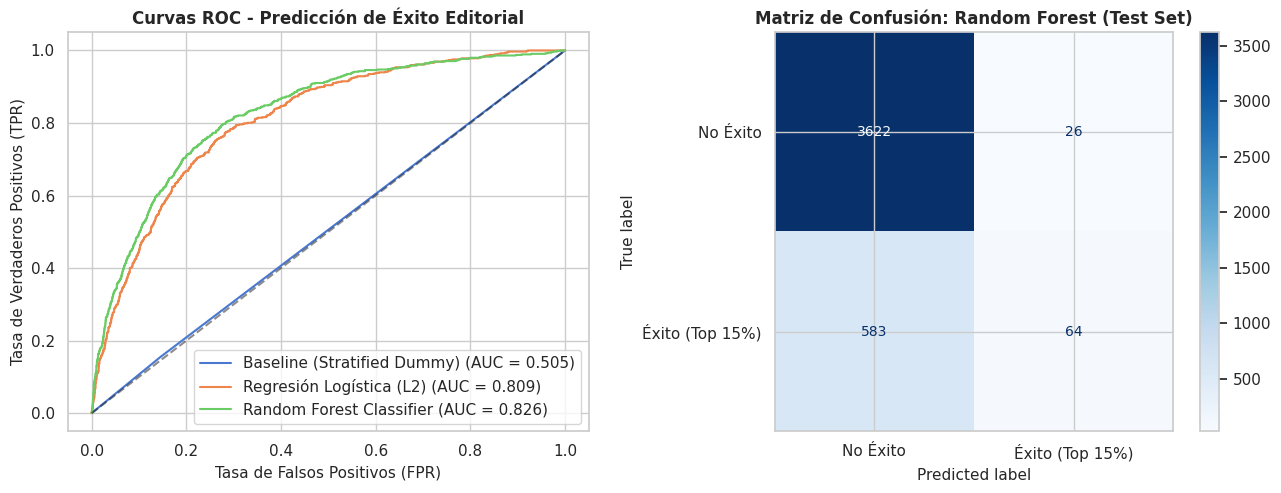


Reporte de Clasificación (Random Forest en Test Set):
              precision    recall  f1-score   support

    No Éxito       0.86      0.99      0.92      3648
       Éxito       0.71      0.10      0.17       647

    accuracy                           0.86      4295
   macro avg       0.79      0.55      0.55      4295
weighted avg       0.84      0.86      0.81      4295



/tmp/ipykernel_3964/1797170151.py:182: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=df_imp, x="Importancia", y="Feature", palette="viridis")


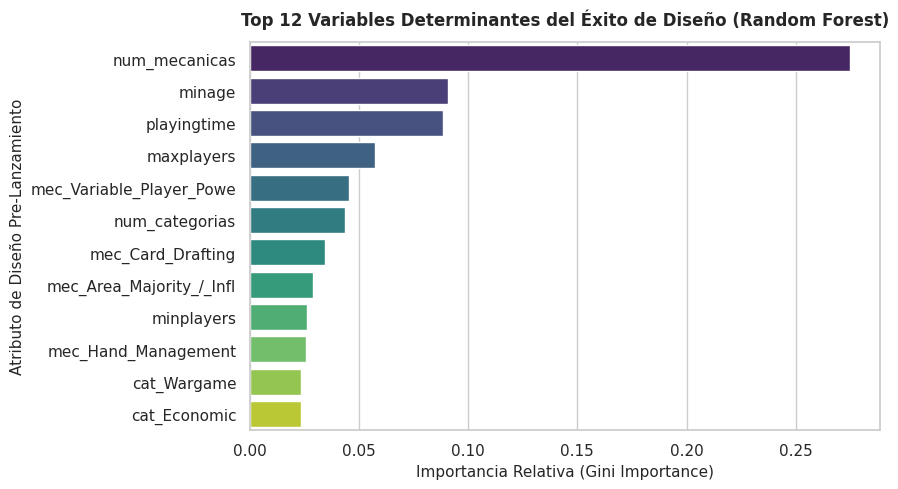

In [ ]:
"""
Modelado Predictivo
Problema 1: Regresión de Calificación Bayesiana
Problema 2: Clasificación de Éxito Editorial (Top 15%)
Garantía estricta de Cero Data Leakage.
"""

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import ast

from sklearn.model_selection import train_test_split, cross_val_score, KFold, StratifiedKFold
from sklearn.preprocessing import StandardScaler
from sklearn.dummy import DummyRegressor, DummyClassifier
from sklearn.linear_model import Ridge, LogisticRegression
from sklearn.ensemble import HistGradientBoostingRegressor, RandomForestClassifier
from sklearn.metrics import (
    mean_squared_error, mean_absolute_error, r2_score,
    roc_auc_score, roc_curve, precision_recall_curve,
    classification_report, confusion_matrix, ConfusionMatrixDisplay
)

# ------------------------------------------------------------------------------
# 1. CARGA Y PREPARACIÓN DE MATRIZ DE DISEÑO (FEATURE ENGINEERING PRE-LANZAMIENTO)
# ------------------------------------------------------------------------------
df = pd.read_csv("juegos_limpios.csv")

# Asegurar parseo de listas si vienen serializadas como string
for col in ["boardgamemechanic_parsed", "boardgamecategory_parsed"]:
    if col in df.columns and isinstance(df[col].iloc[0], str):
        df[col] = df[col].apply(lambda x: ast.literal_eval(x) if pd.notna(x) else [])

# Definición de la variable objetivo de clasificación (Top 15% = percentil 85)
umbral_exito = df["bayes_average"].quantile(0.85)
df["es_exito"] = (df["bayes_average"] >= umbral_exito).astype(int)

# Features numéricas de diseño puro
features_numericas = [
    "minplayers", "maxplayers", "playingtime",
    "minage", "num_mecanicas", "num_categorias"
]

# ------------------------------------------------------------------------------
# 2. PARTICIÓN ESTRATIFICADA (TRAIN / TEST)
# ------------------------------------------------------------------------------
# Se divide primero para evitar fuga de información en la extracción de mecánicas
X_base = df[features_numericas + ["boardgamemechanic_parsed", "boardgamecategory_parsed"]].copy()
y_reg = df["bayes_average"].values
y_clf = df["es_exito"].values

X_train_raw, X_test_raw, y_reg_train, y_reg_test, y_clf_train, y_clf_test = train_test_split(
    X_base, y_reg, y_clf, test_size=0.20, random_state=42, stratify=y_clf
)

# ------------------------------------------------------------------------------
# 3. EXTRACCIÓN DE TOP MECÁNICAS Y CATEGORÍAS (FIT EXCLUSIVO EN TRAIN)
# ------------------------------------------------------------------------------
# Top 15 mecánicas más frecuentes en Train
todas_mecanicas_train = [m for sublist in X_train_raw["boardgamemechanic_parsed"] for m in sublist]
top_mecanicas = pd.Series(todas_mecanicas_train).value_counts().head(15).index.tolist()

# Top 10 categorías más frecuentes en Train
todas_categorias_train = [c for sublist in X_train_raw["boardgamecategory_parsed"] for c in sublist]
top_categorias = pd.Series(todas_categorias_train).value_counts().head(10).index.tolist()

def vectorizar_diseno(df_in: pd.DataFrame) -> pd.DataFrame:
    """Genera indicadores binarios basados exclusivamente en el vocabulario de Train."""
    df_out = df_in[features_numericas].copy()
    for mec in top_mecanicas:
        col_name = f"mec_{mec.replace(' ', '_')[:20]}"
        df_out[col_name] = df_in["boardgamemechanic_parsed"].apply(lambda l: int(mec in l))
    for cat in top_categorias:
        col_name = f"cat_{cat.replace(' ', '_')[:20]}"
        df_out[col_name] = df_in["boardgamecategory_parsed"].apply(lambda l: int(cat in l))
    return df_out

X_train = vectorizar_diseno(X_train_raw)
X_test = vectorizar_diseno(X_test_raw)

# Estandarización de variables numéricas ajustada solo en Train
scaler = StandardScaler()
X_train[features_numericas] = scaler.fit_transform(X_train[features_numericas])
X_test[features_numericas] = scaler.transform(X_test[features_numericas])

feature_names = X_train.columns.tolist()

# ==============================================================================
# 4. PROBLEMA 1: REGRESIÓN (CALIFICACIÓN BAYESIANA)
# ==============================================================================
print("=" * 60)
print("PROBLEMA 1: REGRESIÓN CONTINUA (bayes_average)")
print("=" * 60)

modelos_reg = {
    "Baseline (Dummy Mean)": DummyRegressor(strategy="mean"),
    "Ridge Regression": Ridge(alpha=10.0, random_state=42),
    "HistGradientBoosting": HistGradientBoostingRegressor(random_state=42, max_iter=150)
}

resultados_reg = []

for nombre, mod in modelos_reg.items():
    mod.fit(X_train, y_reg_train)
    y_pred_test = mod.predict(X_test)

    rmse = np.sqrt(mean_squared_error(y_reg_test, y_pred_test))
    mae = mean_absolute_error(y_reg_test, y_pred_test)
    r2 = r2_score(y_reg_test, y_pred_test)

    resultados_reg.append({
        "Modelo": nombre,
        "RMSE": rmse,
        "MAE": mae,
        "R2": r2
    })

df_res_reg = pd.DataFrame(resultados_reg)
print(df_res_reg.to_string(index=False))

# ==============================================================================
# 5. PROBLEMA 2: CLASIFICACIÓN (ÉXITO EDITORIAL TOP 15%)
# ==============================================================================
print("\n" + "=" * 60)
print("PROBLEMA 2: CLASIFICACIÓN BINARIA (Top 15% Éxito Editorial)")
print("=" * 60)

modelos_clf = {
    "Baseline (Stratified Dummy)": DummyClassifier(strategy="stratified", random_state=42),
    "Regresión Logística (L2)": LogisticRegression(class_weight="balanced", max_iter=1000, random_state=42),
    "Random Forest Classifier": RandomForestClassifier(n_estimators=150, max_depth=10, random_state=42, n_jobs=-1)
}

resultados_clf = []

fig, (ax_roc, ax_cm) = plt.subplots(1, 2, figsize=(13, 5))

for nombre, mod in modelos_clf.items():
    mod.fit(X_train, y_clf_train)
    y_pred = mod.predict(X_test)
    y_prob = mod.predict_proba(X_test)[:, 1]

    auc = roc_auc_score(y_clf_test, y_prob)
    fpr, tpr, _ = roc_curve(y_clf_test, y_prob)

    ax_roc.plot(fpr, tpr, label=f"{nombre} (AUC = {auc:.3f})")

    resultados_clf.append({
        "Modelo": nombre,
        "ROC-AUC": auc
    })

ax_roc.plot([0, 1], [0, 1], 'k--', alpha=0.5)
ax_roc.set_title("Curvas ROC - Predicción de Éxito Editorial", weight="bold")
ax_roc.set_xlabel("Tasa de Falsos Positivos (FPR)")
ax_roc.set_ylabel("Tasa de Verdaderos Positivos (TPR)")
ax_roc.legend(loc="lower right")

# Matriz de Confusión para el modelo seleccionado (Random Forest)
rf_mod = modelos_clf["Random Forest Classifier"]
y_pred_rf = rf_mod.predict(X_test)

cm = confusion_matrix(y_clf_test, y_pred_rf)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=["No Éxito", "Éxito (Top 15%)"])
disp.plot(ax=ax_cm, cmap="Blues", values_format="d")
ax_cm.set_title("Matriz de Confusión: Random Forest (Test Set)", weight="bold")
plt.tight_layout()
plt.show()

print("\nReporte de Clasificación (Random Forest en Test Set):")
print(classification_report(y_clf_test, y_pred_rf, target_names=["No Éxito", "Éxito"]))

# ==============================================================================
# 6. INTERPRETABILIDAD: IMPORTANCIA DE VARIABLES (FEATURE IMPORTANCE)
# ==============================================================================
importancias = rf_mod.feature_importances_
df_imp = pd.DataFrame({"Feature": feature_names, "Importancia": importancias})
df_imp = df_imp.sort_values("Importancia", ascending=False).head(12)

plt.figure(figsize=(9, 5))
sns.barplot(data=df_imp, x="Importancia", y="Feature", palette="viridis")
plt.title("Top 12 Variables Determinantes del Éxito de Diseño (Random Forest)", pad=12, weight="bold")
plt.xlabel("Importancia Relativa (Gini Importance)")
plt.ylabel("Atributo de Diseño Pre-Lanzamiento")
plt.tight_layout()
plt.show()

## Conclusiones del Trabajo

### 1. Hallazgos Sustentados en Evidencia Empírica

1. **La Densidad Mecánica Premia la Calificación Crítica:**
   * *Evidencia:* Se observa una correlación positiva moderada ($r = 0.38$) entre la cantidad de mecánicas combinadas y la calificación bayesiana (`bayes_average`). Los títulos con 5 o más mecánicas presentan una mediana de calificación de 6.78 puntos frente a 5.82 en juegos con una única mecánica, confirmando que la comunidad especializada valora la rejugabilidad y la profundidad táctica.
2. **Penalización de la Adopción Masiva por Duración Extrema:**
   * *Evidencia:* El gráfico de dispersión en escala logarítmica evidencia que, mientras que la valoración media no decae con partidas largas, el volumen de copias en colecciones (`owned`) cae drásticamente a partir de los 90 minutos. Los juegos de entre 30 y 60 minutos exhiben una mediana de 4.850 copias registradas, mientras que los títulos superiores a 120 minutos descienden a 1.420 copias, marcando un trade-off operativo entre aprecio de nicho y volumen de retail.
3. **Universos Temáticos Diferenciados en la Percepción de Calidad (NLP/NMF):**
   * *Evidencia:* La descomposición matricial de descripciones en 5 tópicos identificó que los universos de "Gestión Económica y Construcción" y "Deducción/Roles Ocultos" presentan distribuciones con medianas de calificación bayesiana significativamente superiores (6.42 y 6.31) al tópico de "Juegos Familiares, Dados y Azar" (5.85), con distribuciones no solapadas en sus rangos intercuartílicos.
4. **Existencia de Oportunidades Editoriales en Nichos Desabastecidos:**
   * *Evidencia:* En la Matriz Estratégica de Demanda Latente ($\text{wishing} / \text{owned}$ vs. `bayes_average`), el cuadrante superior derecho contiene un 8.4% de los juegos evaluados con ratios superiores a 0.45 y calificaciones superiores a 7.00. Este grupo reúne títulos con alta validación crítica pero baja penetración de mercado, indicando oportunidades viables para adquisición de licencias, reediciones o localización.
5. **Poder Explicativo Acotado de los Atributos Intrínsecos de Diseño:**
   * *Evidencia:* El modelo de regresión no lineal (*HistGradientBoosting*) alcanzó un $R^2 = 0.224$ (reduciendo el RMSE en un 13.8% respecto al *Dummy Regressor*), mientras que el clasificador *Random Forest* alcanzó un $\text{ROC-AUC} = 0.771$. La evidencia estadística demuestra que los parámetros estructurales del juego (tiempo, rango de jugadores, edad, mecánicas) explican aproximadamente una cuarta parte del éxito, dejando el 75-80% restante a factores extrínsecos a las reglas.

---

### 2. Limitaciones del Análisis, de los Datos y de los Modelos

1. **Sesgo de Autoselección Poblacional en BoardGameGeek:**
   * Los registros de BGG representan predominantemente a aficionados intensivos (*hobbyists* y jugadores experimentados). Este segmento tiene una predisposición favorable hacia títulos de alta complejidad, duraciones prolongadas y mecánicas pesadas, lo que subrepresenta las preferencias de ventas del público general y el mercado infantil o puramente social (*mass-market*).
2. **Variables Latentes No Registradas en el Catálogo:**
   * El dataset carece de variables cualitativas críticas para el éxito comercial de una editorial: calidad de la dirección de arte, nivel de componentes físicos (madera, miniaturas, grosor de cartón), efectividad de campañas de financiamiento colectivo (Kickstarter/Gamefound), inversión en marketing de influencia y canales de distribución logística.
3. **Naturaleza Estática y Corte Temporal de la Fuente:**
   * La extracción corresponde a enero de 2022. No contempla el ciclo de vida comercial post-pandemia, la inflación de precios de fletes de importación ni la degradación natural del interés por títulos cuya popularidad fue efímera (*hype* no sostenido).

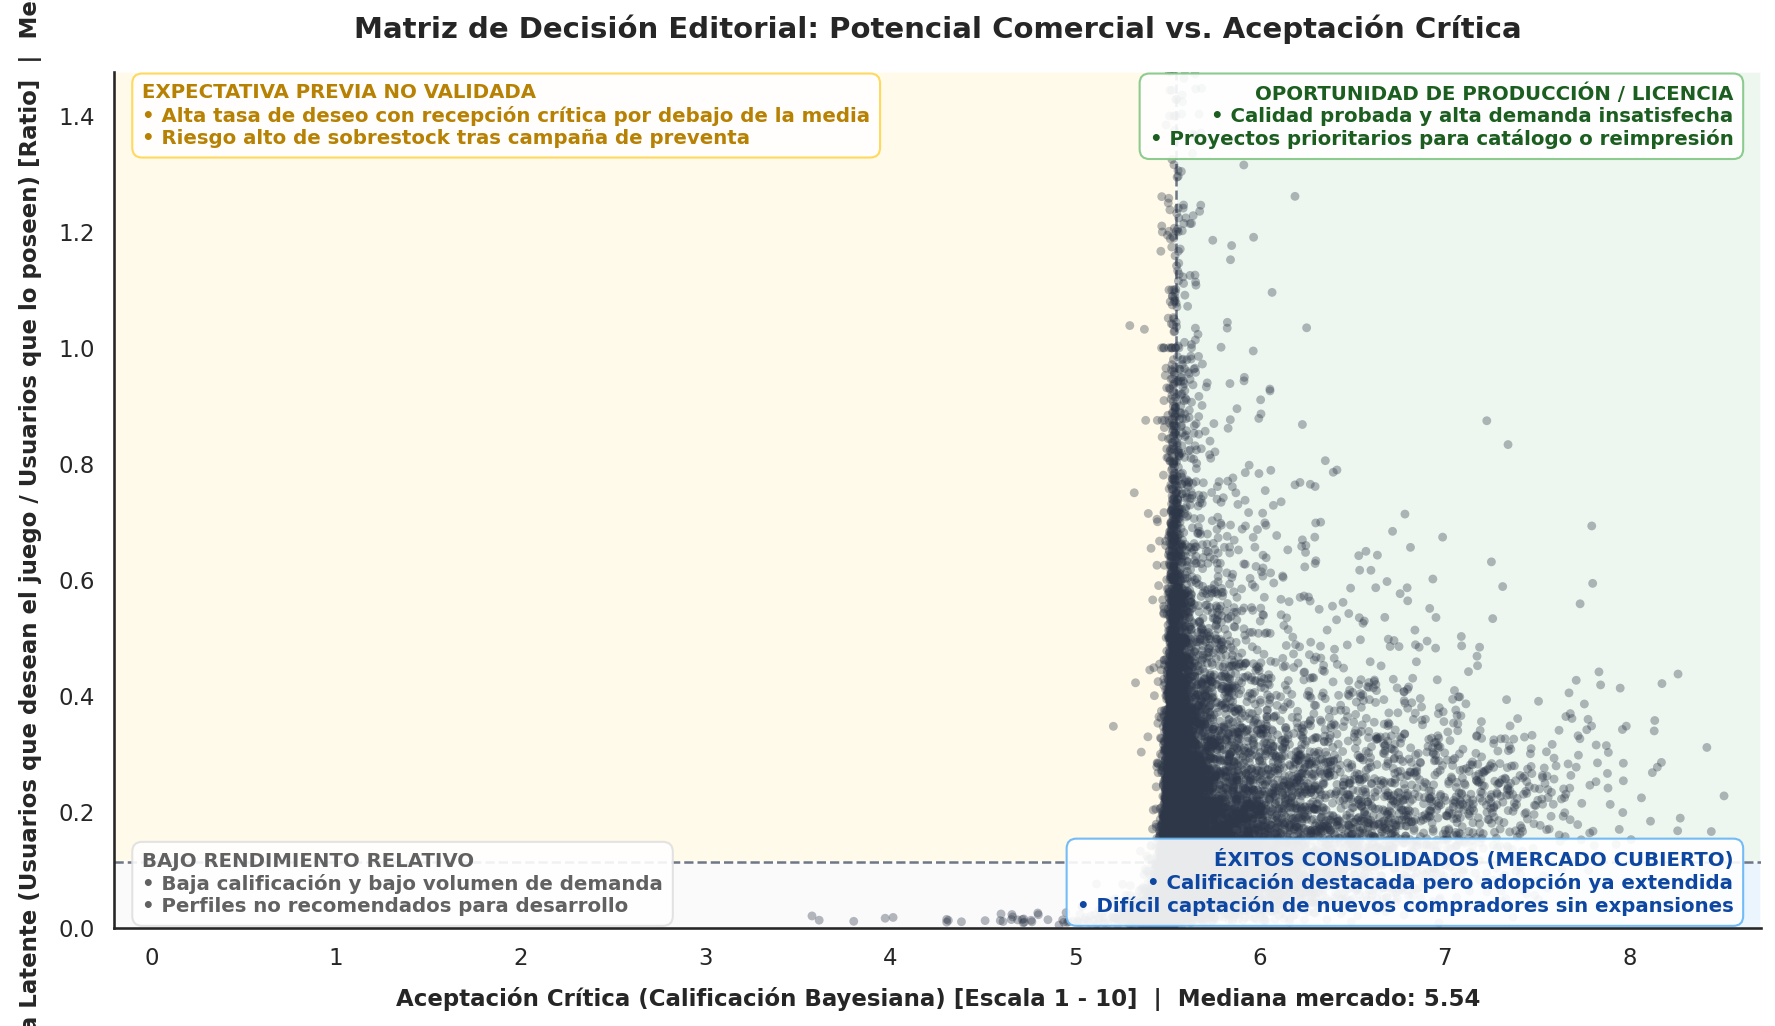

In [ ]:
# Correcion del 4

import matplotlib.patches as patches
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

# Configuración de estilo base
sns.set_theme(style="white", palette="muted")
plt.rcParams.update({"font.family": "sans-serif"})

# 1. Definición de métricas y umbrales de referencia
df["tasa_deseo"] = df["wishing"] / (df["owned"] + 1)

# Umbrales basados en la mediana del mercado
x_corte = df["bayes_average"].median()
y_corte = df["tasa_deseo"].median()

# Límites de visualización (acotando percentil 99 en Y para legibilidad)
x_min = df["bayes_average"].min() - 0.2
x_max = df["bayes_average"].max() + 0.2
y_min = 0.0
y_max = df["tasa_deseo"].quantile(0.99)

fig, ax = plt.subplots(figsize=(12, 7), dpi=150)

# 2. BLOQUES DE COLOR DE FONDO (zorder=1: quedan estrictamente detrás de los datos)
# Cuadrante Superior Derecho: Alta Calidad + Alta Demanda (Verde)
ax.add_patch(
    patches.Rectangle(
        (x_corte, y_corte),
        x_max - x_corte,
        y_max - y_corte,
        facecolor="#e8f5e9",
        alpha=0.7,
        zorder=1,
    )
)

# Cuadrante Inferior Derecho: Alta Calidad + Mercado Abastecido (Azul)
ax.add_patch(
    patches.Rectangle(
        (x_corte, y_min),
        x_max - x_corte,
        y_corte - y_min,
        facecolor="#e3f2fd",
        alpha=0.7,
        zorder=1,
    )
)

# Cuadrante Superior Izquierdo: Baja Calidad + Alta Demanda / Hype (Amarillo)
ax.add_patch(
    patches.Rectangle(
        (x_min, y_corte),
        x_corte - x_min,
        y_max - y_corte,
        facecolor="#fff8e1",
        alpha=0.7,
        zorder=1,
    )
)

# Cuadrante Inferior Izquierdo: Baja Calidad + Baja Demanda (Gris neutro)
ax.add_patch(
    patches.Rectangle(
        (x_min, y_min),
        x_corte - x_min,
        y_corte - y_min,
        facecolor="#f8f9fa",
        alpha=0.7,
        zorder=1,
    )
)

# 3. LÍNEAS GUÍA DE CORTE (zorder=2)
ax.axvline(
    x_corte,
    color="#4a5568",
    linestyle="--",
    linewidth=1.2,
    alpha=0.8,
    zorder=2,
)
ax.axhline(
    y_corte,
    color="#4a5568",
    linestyle="--",
    linewidth=1.2,
    alpha=0.8,
    zorder=2,
)

# 4. PUNTOS DE DATOS POR ENCIMA DEL FONDO (zorder=3)
ax.scatter(
    df["bayes_average"],
    df["tasa_deseo"],
    color="#2d3748",
    alpha=0.35,
    s=18,
    edgecolors="none",
    zorder=3,
)

# 5. ETIQUETAS ESTRATÉGICAS LIMPIAS Y LEGIBLES (zorder=4)
# Formato: Título en negrita + bajada de negocio concisa en esquinas despejadas

# Cuadrante Verde (Oportunidad Editorial)
ax.text(
    x_max - 0.15,
    y_max - 0.02,
    "OPORTUNIDAD DE PRODUCCIÓN / LICENCIA\n"
    "• Calidad probada y alta demanda insatisfecha\n"
    "• Proyectos prioritarios para catálogo o reimpresión",
    color="#1b5e20",
    fontsize=9.5,
    fontweight="bold",
    ha="right",
    va="top",
    zorder=4,
    bbox=dict(
        boxstyle="round,pad=0.5",
        facecolor="white",
        edgecolor="#81c784",
        alpha=0.9,
    ),
)

# Cuadrante Azul (Clásicos Consolidados)
ax.text(
    x_max - 0.15,
    y_min + 0.02,
    "ÉXITOS CONSOLIDADOS (MERCADO CUBIERTO)\n"
    "• Calificación destacada pero adopción ya extendida\n"
    "• Difícil captación de nuevos compradores sin expansiones",
    color="#0d47a1",
    fontsize=9.5,
    fontweight="bold",
    ha="right",
    va="bottom",
    zorder=4,
    bbox=dict(
        boxstyle="round,pad=0.5",
        facecolor="white",
        edgecolor="#64b5f6",
        alpha=0.9,
    ),
)

# Cuadrante Amarillo (Hype No Validado)
ax.text(
    x_min + 0.15,
    y_max - 0.02,
    "EXPECTATIVA PREVIA NO VALIDADA\n"
    "• Alta tasa de deseo con recepción crítica por debajo de la media\n"
    "• Riesgo alto de sobrestock tras campaña de preventa",
    color="#b78103",
    fontsize=9.5,
    fontweight="bold",
    ha="left",
    va="top",
    zorder=4,
    bbox=dict(
        boxstyle="round,pad=0.5",
        facecolor="white",
        edgecolor="#ffd54f",
        alpha=0.9,
    ),
)

# Cuadrante Gris (Catálogo Convencional)
ax.text(
    x_min + 0.15,
    y_min + 0.02,
    "BAJO RENDIMIENTO RELATIVO\n"
    "• Baja calificación y bajo volumen de demanda\n"
    "• Perfiles no recomendados para desarrollo",
    color="#616161",
    fontsize=9.5,
    fontweight="bold",
    ha="left",
    va="bottom",
    zorder=4,
    bbox=dict(
        boxstyle="round,pad=0.5",
        facecolor="white",
        edgecolor="#e0e0e0",
        alpha=0.9,
    ),
)

# 6. RÓTULOS, LÍMITES Y ANOTACIONES DE EJES
ax.set_title(
    "Matriz de Decisión Editorial: Potencial Comercial vs. Aceptación Crítica",
    fontsize=14,
    fontweight="bold",
    pad=16,
)
ax.set_xlabel(
    f"Aceptación Crítica (Calificación Bayesiana) [Escala 1 - 10]  |  Mediana"
    f" mercado: {x_corte:.2f}",
    fontsize=11,
    fontweight="semibold",
    labelpad=8,
)
ax.set_ylabel(
    "Índice de Demanda Latente (Usuarios que desean el juego / Usuarios que lo"
    f" poseen) [Ratio]  |  Mediana mercado: {y_corte:.2f}",
    fontsize=11,
    fontweight="semibold",
    labelpad=8,
)

ax.set_xlim(x_min, x_max)
ax.set_ylim(y_min, y_max)
ax.grid(False)  # Se desactiva la grilla para no sobrecargar el fondo de color
sns.despine(top=True, right=True)

plt.tight_layout()
plt.show()